# KSA National Forest Inventory (NFI)
# National Geopipeline · User Guide Notebook (V5)

**Scope:** entire Kingdom of Saudi Arabia tabular universe (all regions in the cleansed SU master).  
**Not:** an Asir-only or few-region demo.

| Item | Value |
| --- | --- |
| Package | `NFI_Comprehensive_Expanded_V5` (GitHub) / `12.NFI_Comprehensive_Expanded_V5` (local) |
| Outputs | `outputs_national_v5/` (never overwrites raw data) |
| Formulas | `data/docs/NFI_ KSA Calculation_Trees&shrubs.docx` |
| HTML report | `outputs_national_v5/documents/NFI_national_geopipeline_report.html` |
| Interactive atlas | `outputs_national_v5/maps/html_atlas/index.html` |
| Companion deep-dive | `NFI_GeoAI_Comprehensive_Expanded_V5.ipynb` (Part A Asir GIS + Part B LULC) |
| CLI twin | `python run_national_pipeline.py` |
| Colab open | [Open this notebook in Colab](https://colab.research.google.com/github/gabrielsanya-ops/NFI_Comprehensive_Expanded_V5/blob/master/NFI_National_GeoPipeline_Guide_V5.ipynb) |

---


## Colab bootstrap (run first on Google Colab)

**User note:** On Colab, run the next code cell once. It will:
1. Mount Google Drive if available (optional),
2. Else clone `https://github.com/gabrielsanya-ops/NFI_Comprehensive_Expanded_V5`,
3. `chdir` into the package root,
4. Print the **associated data folder tree** (`data/cleansed`, `data/shapefile`, `data/lulc`, `data/docs`),
5. Install lightweight requirements if needed.

Expected layout after bootstrap:

```text
NFI_Comprehensive_Expanded_V5/
├── NFI_National_GeoPipeline_Guide_V5.ipynb
├── config.yaml
├── src/
├── data/
│   ├── cleansed/          <- national Excel tables
│   ├── shapefile/         <- Asir + Makkah GIS
│   ├── lulc/              <- validated LULC products
│   └── docs/              <- calc DOCX + extracts
├── docs/
├── outputs_national_v5/   <- created when you run the pipeline
└── requirements.txt
```


In [ ]:
from pathlib import Path
import os, sys, subprocess, shutil, warnings
warnings.filterwarnings("ignore")

REPO_URL = "https://github.com/gabrielsanya-ops/NFI_Comprehensive_Expanded_V5.git"
CLONE_DIR = Path("/content/NFI_Comprehensive_Expanded_V5")
ALIASES = [
    "NFI_Comprehensive_Expanded_V5",
    "12.NFI_Comprehensive_Expanded_V5",
]

def looks_like_root(p: Path) -> bool:
    return (p / "config.yaml").exists() and (p / "src").exists() and (p / "data" / "cleansed").exists()

IN_COLAB = Path("/content").exists()
if IN_COLAB:
    try:
        from google.colab import drive
        try:
            drive.mount("/content/drive", force_remount=False)
        except Exception as e:
            print("Drive mount skipped/failed:", e)
    except Exception:
        pass

candidates = []
drive_root = Path("/content/drive/MyDrive")
for name in ALIASES:
    candidates += [
        drive_root / name,
        drive_root / "33.Projects" / name,
        Path("/content") / name,
        Path(r"F:/1.KSA/29.NFI") / name,
        Path(r"F:/1.KSA/29.NFI/12.NFI_Comprehensive_Expanded_V5"),
    ]
candidates += [Path.cwd(), CLONE_DIR]

ROOT = next((c.resolve() for c in candidates if c.exists() and looks_like_root(c)), None)
if ROOT is None and IN_COLAB:
    print("Package not found on Drive: cloning from GitHub (includes data/)...")
    if CLONE_DIR.exists():
        shutil.rmtree(CLONE_DIR, ignore_errors=True)
    subprocess.check_call(["git", "clone", "--depth", "1", REPO_URL, str(CLONE_DIR)])
    ROOT = CLONE_DIR.resolve()

if ROOT is None or not looks_like_root(ROOT):
    raise FileNotFoundError(
        "Could not locate package with data/cleansed. "
        "Sync folder to Drive or ensure the GitHub repo is public, then re-run."
    )

os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

# Lightweight deps for national guide (skip heavy GIS rebuild if already present)
need = []
for pkg, mod in [("folium", "folium"), ("geopandas", "geopandas"), ("openpyxl", "openpyxl"), ("pyyaml", "yaml")]:
    try:
        __import__(mod)
    except Exception:
        need.append(pkg)
if need:
    print("Installing:", need)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need])

def tree(path: Path, prefix: str = "", max_files: int = 12):
    entries = sorted(path.iterdir(), key=lambda p: (not p.is_dir(), p.name.lower()))
    dirs = [e for e in entries if e.is_dir() and e.name not in {".git", "__pycache__", ".pytest_cache"}]
    files = [e for e in entries if e.is_file()]
    shown = dirs + files[:max_files]
    for i, e in enumerate(shown):
        last = i == len(shown) - 1 and len(files) <= max_files
        branch = "+-- " if last else "|-- "
        print(prefix + branch + e.name + ("/" if e.is_dir() else ""))
        if e.is_dir() and e.name in {"data", "cleansed", "shapefile", "lulc", "docs", "src", "Asir_NFI_Shapefiles", "Makkah_NFI_Shapefiles"}:
            tree(e, prefix + ("    " if last else "|   "), max_files=10)
    if len(files) > max_files:
        print(prefix + f"+-- ... {len(files) - max_files} more files")

print("IN_COLAB:", IN_COLAB)
print("ROOT    :", ROOT)
print()
print("Package folder structure (associated data highlighted under data/):")
print(ROOT.name + "/")
tree(ROOT)
print()
print("cleansed xlsx:", sorted(p.name for p in (ROOT / "data" / "cleansed").glob("*.xlsx")))
print("shapefile dirs:", sorted(p.name for p in (ROOT / "data" / "shapefile").iterdir() if p.is_dir()))
print("Ready. Continue with Section 0 (imports) or Section 16 one-shot.")


## User guide (read first)

### Who this notebook is for
Analysts and reviewers who need a **national** NFI geopipeline: ingest → anti-clip lattice → tree and shrub biomass (official calc document) → EDA → **static maps** → **interactive Leaflet HTML** → **HTML report**.

### How to run (recommended order)
1. Run **Section 0** (bootstrap) once.
2. Skim **Section 1** (scope and design rules).
3. Run **Sections 2 to 15** in order (step-by-step, easiest to audit).
4. Or jump to **Section 16** for a one-shot full pipeline (same code as the CLI; includes HTML products).
5. Finish with **Section 17 to 18** (outputs checklist and assumptions).

### Colab
1. Runtime → Connect.  
2. Run Section 0 bootstrap (clones package if needed).  
3. Continue from Section 1.  
4. After Section 14/15, open the HTML report and atlas from the printed paths (download from Colab files if needed).

### Design rules baked into this notebook
- **No invented numbers.** Only formulas from the calc DOCX / extract, or values actually computed from data.
- **National LEFT master.** The SU table defines the frame. GIS Area_H is optional and only available for Asir and Makkah in this workspace.
- **Anti-clip.** Zero-tree and zero-shrub SUs stay in the lattice.
- **Provisional carbon.** Sample metrics until design weights and full Area_H exist.
- **HTML is optional but recommended** for sharing: report + interactive maps are produced from the same computed objects.
- **No em dashes** in project text products (project house style).

### Quick map of sections

| Section | What you get |
| --- | --- |
| 0 | Environment, paths, imports |
| 1 | Scope, formula overview, what is blocked |
| 2 | Load `config.yaml` |
| 3 | Load all cleansed tables (national) |
| 4 | Universe KPIs by region |
| 5 | SU × 5 plot anti-clip lattice |
| 6 | Tree and shrub presence gates |
| 7 | Optional Area_H attach |
| 8 | Tree biomass chain (calc DOCX) |
| 9 | Shrub biomass chain (calc DOCX) |
| 10 | Ancillary pools (counts only) |
| 11 | Land-use proportions |
| 12 | Univariate / bivariate EDA figures |
| 13 | Static national PNG maps |
| 14 | **Interactive Leaflet HTML maps + atlas portal** |
| 15 | **HTML methodology report (LULC-style)** |
| 16 | One-shot `run_national_pipeline` (includes HTML) |
| 17 | Verify output files |
| 17b | **Deliverables: map HTML + report HTML links** |
| 18 | Assumptions and open questions |
| Appendix | CLI, file map, Part A pointer |


<a id="s0"></a>
## 0 · Bootstrap and environment

**User note:** Run this cell first (local or Colab). It finds the package root, puts `src/` on `sys.path`, and loads config helpers. On Colab it can clone the public package if Drive is empty.


In [ ]:
from pathlib import Path
import os, sys, json, warnings, subprocess
warnings.filterwarnings("ignore")

def _find_root() -> Path:
    candidates = [
        Path(r"F:/1.KSA/29.NFI/12.NFI_Comprehensive_Expanded_V5"),
        Path.cwd(),
        Path.cwd().parent,
    ]
    drive = Path("/content/drive/MyDrive")
    if drive.exists():
        candidates.extend(drive.rglob("12.NFI_Comprehensive_Expanded_V5"))
    for p in candidates:
        try:
            if (p / "config.yaml").exists() and (p / "src").exists():
                return p.resolve()
        except Exception:
            continue
    if Path("/content").exists():
        dest = Path("/content/NFI_Comprehensive_Expanded_V5")
        if not (dest / "config.yaml").exists():
            subprocess.run(
                ["git", "clone", "--depth", "1",
                 "https://github.com/gabrielsanya-ops/NFI_Comprehensive_Expanded_V5.git",
                 str(dest)],
                check=False,
            )
        if (dest / "config.yaml").exists():
            return dest.resolve()
    return Path.cwd().resolve()

ROOT = _find_root()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

from nfi_audit import (
    load_config, resolve_portable_paths, ensure_output_dirs, StageStore,
)
from nfi_calc_biomass import (
    FORM_FACTOR, WOOD_DENSITY, BEF, ROOT_SHOOT, CARBON_FRACTION, CO2EQ_FACTOR,
    CONVERSION_FACTOR_HA, TREE_EXCLUDE, SHRUB_EXCLUDE,
)
from nfi_national_pipeline import (
    load_national_tables, national_universe_summary, build_national_plot_lattice,
    national_gate_tree_presence, national_shrub_gate, attach_regional_gis_area,
    national_tree_biomass, national_shrub_biomass, aggregate_plot_su_metrics,
    national_ancillary_inventory, national_land_use_proportions,
    write_national_eda_figures, write_national_maps, run_national_pipeline,
)
from nfi_national_html import (
    write_national_interactive_maps, write_national_html_atlas,
    write_national_html_report, produce_national_html_products,
)
from nfi_datascience import missingness_report, univariate_numeric
from IPython.display import display, Markdown, Image, IFrame, HTML
import pandas as pd

CFG = resolve_portable_paths(load_config(ROOT / "config.yaml"), ROOT)
OUT = Path(CFG["paths"].get("output_national_root", ROOT / "outputs_national_v5"))
if not OUT.is_absolute():
    OUT = ROOT / OUT
OUT = ensure_output_dirs({**CFG, "paths": {**CFG["paths"], "output_root": str(OUT)}})
STAGES = StageStore(OUT)
HTML_PRODUCTS = {}

print("ROOT:", ROOT)
print("OUT :", OUT)
print("plots_per_su_design:", CFG["project"]["plots_per_su_design"])
print("Ready (includes HTML report + interactive map modules).")


<a id="s1"></a>
## 1 · Scope and formula overview

**User note:** Documentation only (no heavy compute). Confirm the frame and official constants before biomass cells.

### National frame
- LEFT master = cleansed SU table for **all regions**
- Design = **5 plots per SU** → expected lattice = `n_su × 5`

### Official tree chain (calc DOCX)
`BA → Volume (FF=0.65) → AGB (WD=0.6 × BEF=2) → BGB (×0.28) → Carbon (×0.47) → CO2eq (×3.67)`  
Per-ha sample scaling uses **conversion factor = 10**.

### Official shrub chain (calc DOCX)
`mean_CD_m`, height in **cm** → allometric AGB → BGB (×0.28) → Carbon (×0.47)  
Shrub **CO2eq is not stated** in the DOCX shrub section → left blank on purpose.

### HTML products (this notebook)
- Interactive Leaflet maps under `maps/html_interactive/`
- Atlas portal `maps/html_atlas/index.html`
- Shareable report `documents/NFI_national_geopipeline_report.html`


In [ ]:
constants = {
    "form_factor": FORM_FACTOR,
    "wood_density": WOOD_DENSITY,
    "bef": BEF,
    "root_shoot": ROOT_SHOOT,
    "carbon_fraction": CARBON_FRACTION,
    "co2eq_factor": CO2EQ_FACTOR,
    "conversion_factor_ha": CONVERSION_FACTOR_HA,
    "tree_exclude_substrings": list(TREE_EXCLUDE),
    "shrub_exclude_substrings": list(SHRUB_EXCLUDE),
}
display(Markdown("### Active constants"))
display(constants)


<a id="s2"></a>
## 2 · Configuration snapshot

**User note:** Paths resolve relative to the package root. GIS key fields are column names, not files.


In [ ]:
rows = []
for section in ("project", "policy", "tree_biomass"):
    for k, v in (CFG.get(section) or {}).items():
        rows.append({"section": section, "key": k, "value": str(v)[:120]})
for section in ("tables", "gis", "paths"):
    for k, v in (CFG.get(section) or {}).items():
        exists = None
        if isinstance(v, str) and (any(x in str(v) for x in ("/", "\\")) or str(v).endswith((".xlsx", ".shp", ".csv", ".docx", ".md"))):
            exists = Path(str(v)).exists()
        rows.append({"section": section, "key": k, "value": str(v)[:100], "exists": exists})
cfg_df = pd.DataFrame(rows)
display(cfg_df.head(40))
cfg_df.to_csv(OUT / "audit" / "guide_config_snapshot.csv", index=False)


<a id="s3"></a>
## 3 · National ingest (all cleansed tables)

**User note:** Entire country table set with `SU_UID` / `PLOT_UID` keys. Not an Asir filter.


In [ ]:
TABLES = load_national_tables(CFG)
su, plot = TABLES["su"], TABLES["plot"]
trees, shrubs = TABLES["trees"], TABLES["shrubs"]

inventory = pd.DataFrame([
    {
        "table": name,
        "rows": len(df),
        "n_su": int(df["SU_UID"].nunique()) if "SU_UID" in df.columns else None,
        "n_plot_uid": int(df["PLOT_UID"].nunique()) if "PLOT_UID" in df.columns else None,
    }
    for name, df in TABLES.items()
]).sort_values("rows", ascending=False)
display(Markdown("### Table inventory (national)"))
display(inventory)
inventory.to_csv(OUT / "audit" / "guide_table_inventory.csv", index=False)
STAGES.save("G03_ingest", "inventory", inventory, note="National table inventory")
print("SU rows:", len(su), "| Plot rows:", len(plot), "| Trees:", len(trees), "| Shrubs:", len(shrubs))


<a id="s4"></a>
## 4 · Universe summary by region

**User note:** National KPI board. Confirm `n_su` and plots-per-SU before gates.


In [ ]:
SUMMARY = national_universe_summary(su, plot, CFG)
by_region = SUMMARY["by_region"]
display(Markdown("### Sampling units by region"))
display(by_region)
by_region.to_csv(OUT / "audit" / "national_su_by_region.csv", index=False)
kpis = {
    "n_su": SUMMARY["n_su"],
    "n_su_unique": SUMMARY["n_su_unique"],
    "n_plot_rows": SUMMARY["n_plot_rows"],
    "n_plot_uid": SUMMARY["n_plot_uid"],
    "plots_per_su_min": SUMMARY["plots_per_su_min"],
    "plots_per_su_max": SUMMARY["plots_per_su_max"],
    "plots_per_su_all_equal_5": SUMMARY["plots_per_su_all_equal_5"],
    "n_regions": SUMMARY["n_regions"],
    "expected_lattice": SUMMARY["n_su"] * int(CFG["project"]["plots_per_su_design"]),
}
display(Markdown("### Headline KPIs"))
display(kpis)
pd.DataFrame([kpis]).to_csv(OUT / "audit" / "guide_national_kpis.csv", index=False)


<a id="s5"></a>
## 5 · Anti-clip plot lattice (SU × 5)

**User note:** Every SU contributes five plot slots even when no trees exist.


In [ ]:
LATTICE = build_national_plot_lattice(su, trees, CFG)
expected = SUMMARY["n_su"] * int(CFG["project"]["plots_per_su_design"])
assert len(LATTICE) == expected, f"Lattice {len(LATTICE)} != expected {expected}"
LATTICE.to_csv(OUT / "validated" / "national_plot_lattice.csv", index=False)
STAGES.save("G05_lattice", "lattice_head", LATTICE.head(5000), note="National anti-clip lattice sample")
display(LATTICE.head(10))
print("Lattice rows:", len(LATTICE), "| with tree records:", int(LATTICE["has_tree_record"].sum()))


<a id="s6"></a>
## 6 · Presence gates (trees and shrubs)

**User note:** Gates list zero-tree / zero-shrub SUs. They do not delete those SUs from the lattice.


In [ ]:
GATE_T = national_gate_tree_presence(su, trees)
GATE_S = national_shrub_gate(su, shrubs)
gate_summary = pd.DataFrame([
    {"pool": "trees", "total_sus": GATE_T["total_sus"], "with_records": GATE_T["sus_with_trees"], "zero_sus": GATE_T["sus_no_trees"]},
    {"pool": "shrubs", "total_sus": GATE_S["total_sus"], "with_records": GATE_S["sus_with_shrubs"], "zero_sus": GATE_S["sus_no_shrubs"]},
])
display(gate_summary)
gate_summary.to_csv(OUT / "gates" / "national_gate_presence_summary.csv", index=False)
pd.DataFrame([{k: GATE_T[k] for k in ("total_sus", "sus_with_trees", "sus_no_trees")}]).to_csv(
    OUT / "gates" / "national_gate_tree_presence.csv", index=False
)
pd.DataFrame([{k: GATE_S[k] for k in ("total_sus", "sus_with_shrubs", "sus_no_shrubs")}]).to_csv(
    OUT / "gates" / "national_gate_shrub_presence.csv", index=False
)
pd.DataFrame({"SU_UID": GATE_T["zero_tree_su_uids"]}).to_csv(OUT / "gates" / "national_zero_tree_su_uids.csv", index=False)
pd.DataFrame({"SU_UID": GATE_S["zero_shrub_su_uids"]}).to_csv(OUT / "gates" / "national_zero_shrub_su_uids.csv", index=False)


<a id="s7"></a>
## 7 · Optional GIS Area_H (Asir and Makkah only)

**User note:** Left-joins Area_H where shapefiles exist; never drops non-GIS SUs.


In [ ]:
SU_AREA = attach_regional_gis_area(su, CFG)
SU_AREA.to_csv(OUT / "validated" / "national_su_with_optional_area.csv", index=False)
AREA_COV = SU_AREA["area_status"].value_counts(dropna=False).rename("n").reset_index()
AREA_COV.columns = ["area_status", "n"]
display(AREA_COV)
AREA_COV.to_csv(OUT / "audit" / "national_area_coverage.csv", index=False)
print("GIS Area_H attached:", int((SU_AREA['area_status']=='GIS_AREA_ATTACHED').sum()))
print("Blocked (no grid):", int((SU_AREA['area_status']=='AREA_BLOCKED_NO_GRID').sum()))


<a id="s8"></a>
## 8 · Tree biomass (calc DOCX)

**User note:** Provisional sample metrics. Not design-based inventory totals.


In [ ]:
TREE_M = national_tree_biomass(trees, CFG)
TREE_M.to_csv(OUT / "validated" / "national_trees_biomass_provisional.csv", index=False)
uni_t = univariate_numeric(TREE_M, [c for c in ["basal_area_m2", "volume_m3", "agb_mg", "carbon_mg_provisional", "co2eq_mg_provisional"] if c in TREE_M.columns])
display(uni_t)
uni_t.to_csv(OUT / "audit" / "univariate_national_trees_fv.csv", index=False)
print("Tree biomass rows:", len(TREE_M))
display(TREE_M[["SU_UID", "PLOT_UID", "basal_area_m2", "volume_m3", "agb_mg", "carbon_mg_provisional"]].head(8))


<a id="s9"></a>
## 9 · Shrub biomass (calc DOCX)

**User note:** Height converted to cm when field looks like metres. Natural-log assumption. Shrub CO2eq stays blank.


In [ ]:
SHRUB_M = national_shrub_biomass(shrubs)
SHRUB_M.to_csv(OUT / "validated" / "national_shrubs_biomass_provisional.csv", index=False)
uni_s = univariate_numeric(SHRUB_M, [c for c in ["mean_CD_m", "height_cm", "agb_mg", "carbon_mg_provisional"] if c in SHRUB_M.columns])
display(uni_s)
uni_s.to_csv(OUT / "audit" / "univariate_national_shrubs_fv.csv", index=False)
print("Shrub biomass rows:", len(SHRUB_M))
print("co2eq all-null (expected):", bool(SHRUB_M["co2eq_mg_provisional"].isna().all()))
display(SHRUB_M[["SU_UID", "PLOT_UID", "mean_CD_m", "height_cm", "agb_mg", "carbon_mg_provisional"]].head(8))


<a id="s10"></a>
## 10 · Ancillary pools (inventory only)

**User note:** Counted only. Biomass blocked: no calc-doc equations for these pools.


In [ ]:
ANCILLARY = national_ancillary_inventory(TABLES, OUT / "audit")
display(ANCILLARY)


<a id="s11"></a>
## 11 · Land-use proportions by SU

**User note:** Plot class counts within each SU divided by 5 plots (calc-doc design).


In [ ]:
LU = national_land_use_proportions(TABLES["lucs"], CFG, OUT / "validated") if "lucs" in TABLES else pd.DataFrame()
display(LU.head(12))
print("LU proportion rows:", len(LU))


<a id="s12"></a>
## 12 · Univariate and bivariate analysis (shown in this notebook)

**User note:** This section is the main statistical view. It prints:
1. Univariate summary tables for trees and shrubs,
2. Bivariate Spearman / Pearson correlation tables,
3. The corresponding PNG figures inline.

Sample SU roll-ups (CF=10) are written alongside for the HTML report.


### Univariate · trees (provisional FV)

variable,n,mean,std,min,p25,median,p75,max,skew,mean_median_gap
agb_mg,12231,0.025884,0.083575,0.000008,0.003677,0.006839,0.017079,2.549440,11.192757,0.019045
carbon_mg_provisional,12231,0.015572,0.050279,0.000005,0.002212,0.004114,0.010274,1.533743,11.192757,0.011457
volume_m3,12231,0.021570,0.069646,0.000006,0.003064,0.005699,0.014232,2.124533,11.192757,0.015871


### Univariate · shrubs (provisional)

variable,n,mean,std,min,p25,median,p75,max,skew,mean_median_gap
mean_CD_m,4823,2.088583,1.127362,0.250000,1.300000,1.950000,2.600000,17.000000,1.974538,0.138583
height_cm,4823,161.064690,136.512090,11.000000,110.000000,160.000000,200.000000,8000.000000,39.501511,1.064690
agb_mg,4823,0.112952,0.181204,0.001751,0.026947,0.066094,0.136179,4.800139,9.342849,0.046859
carbon_mg_provisional,4823,0.067952,0.109012,0.001054,0.016211,0.039762,0.081926,2.887764,9.342849,0.028190


### Bivariate · Spearman (trees)

Unnamed: 0,var_a,var_b,method,corr
3,volume_m3,agb_mg,spearman,1.000000
5,agb_mg,carbon_mg_provisional,spearman,1.000000
4,volume_m3,carbon_mg_provisional,spearman,1.000000
0,basal_area_m2,volume_m3,spearman,0.957194
1,basal_area_m2,agb_mg,spearman,0.957193
2,basal_area_m2,carbon_mg_provisional,spearman,0.957193


### Bivariate · Pearson (trees)

Unnamed: 0,var_a,var_b,method,corr
3,volume_m3,agb_mg,pearson,1.000000
4,volume_m3,carbon_mg_provisional,pearson,1.000000
5,agb_mg,carbon_mg_provisional,pearson,1.000000
1,basal_area_m2,agb_mg,pearson,0.864565
0,basal_area_m2,volume_m3,pearson,0.864565
2,basal_area_m2,carbon_mg_provisional,pearson,0.864565


### Univariate and bivariate figures

**univariate_trees_national.png**

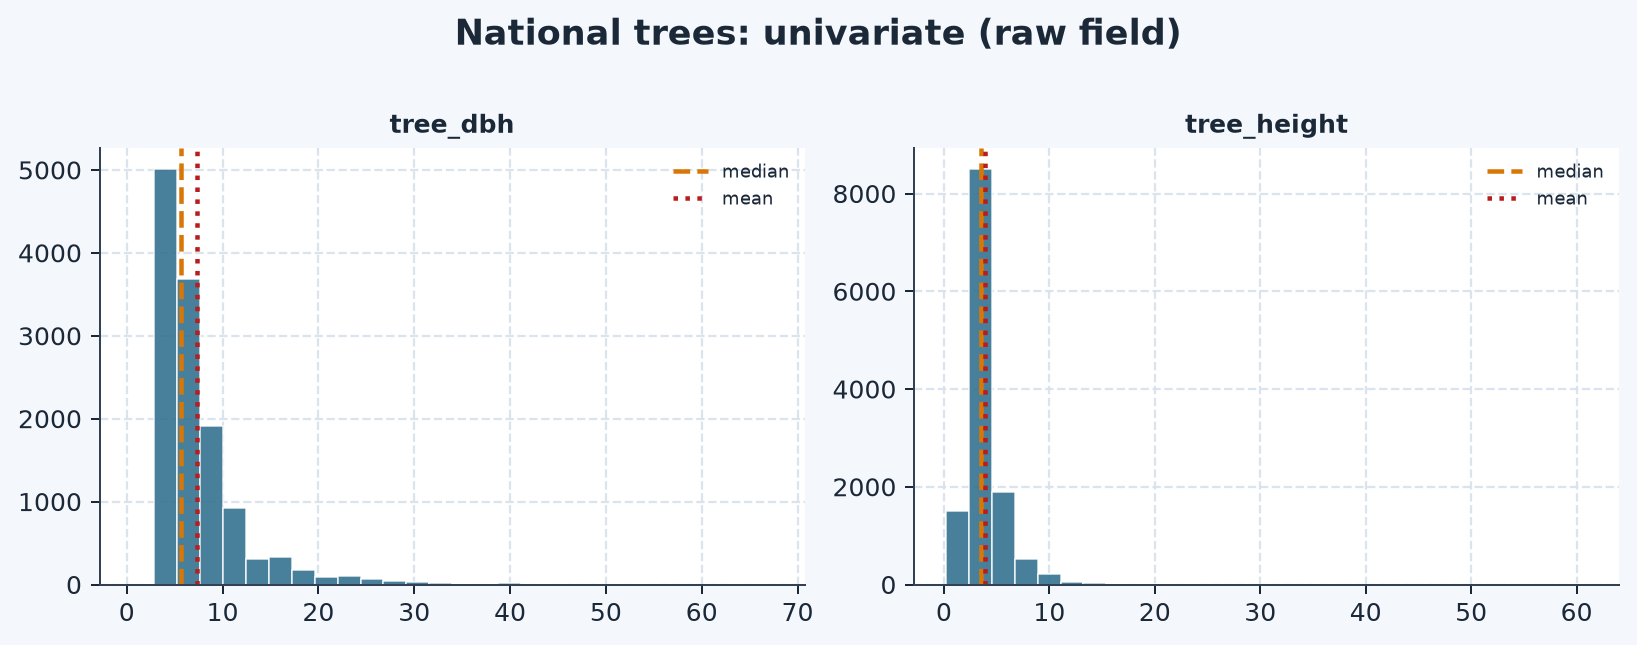

**univariate_trees_fv_national.png**

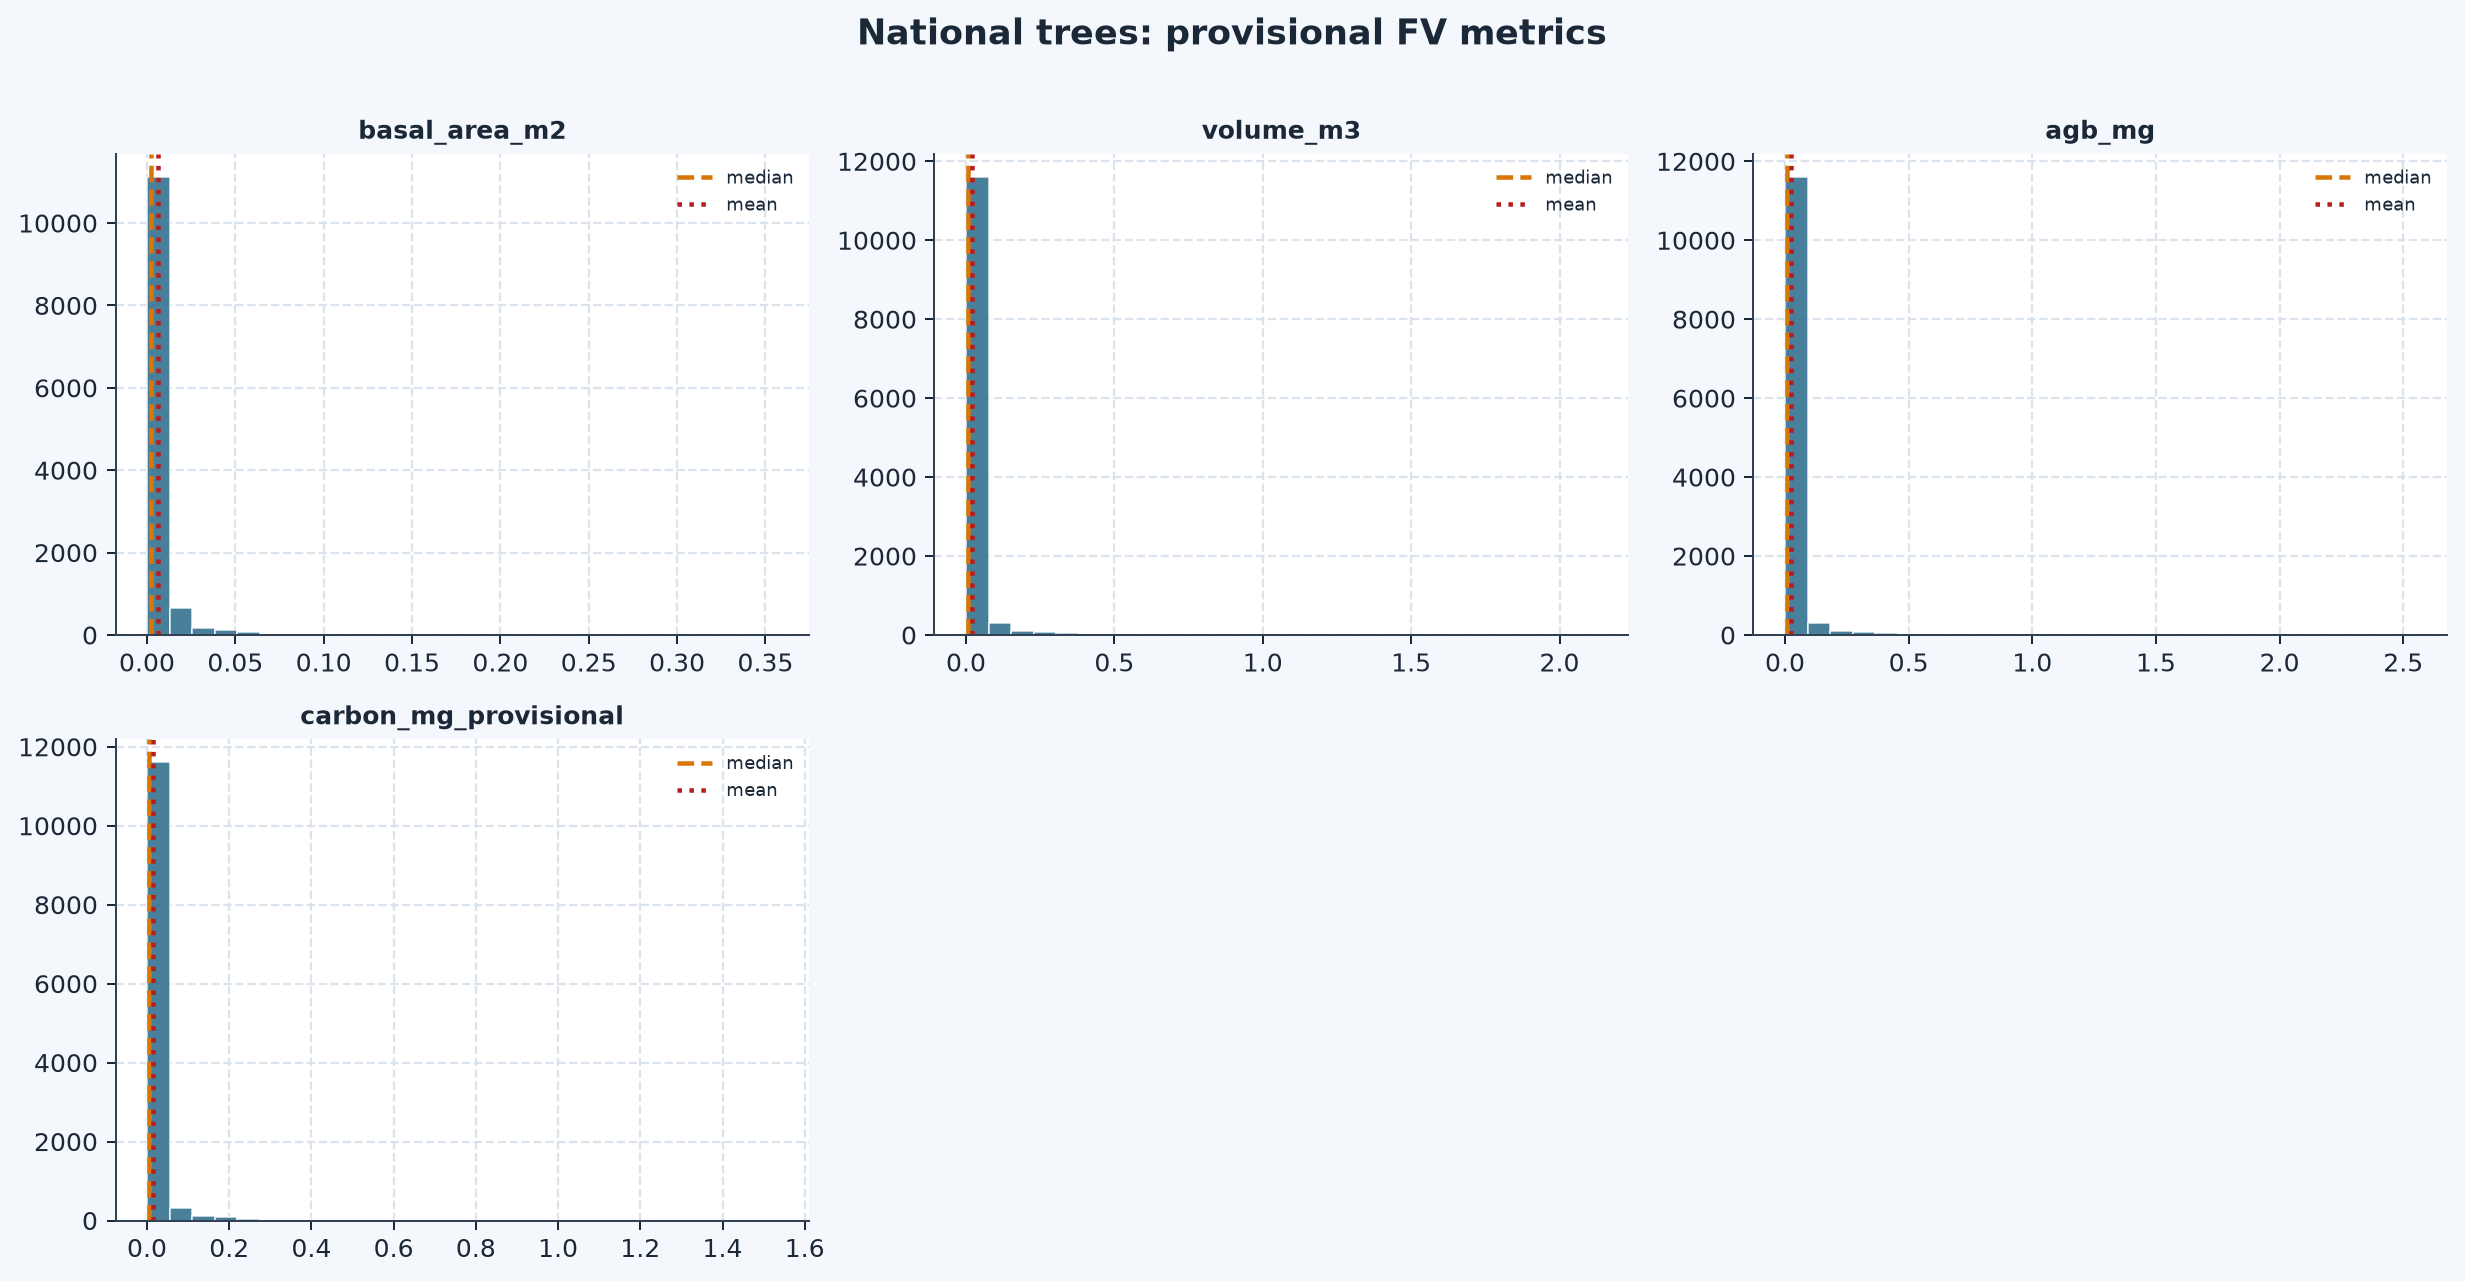

**bivariate_corr_pair_trees_national.png**

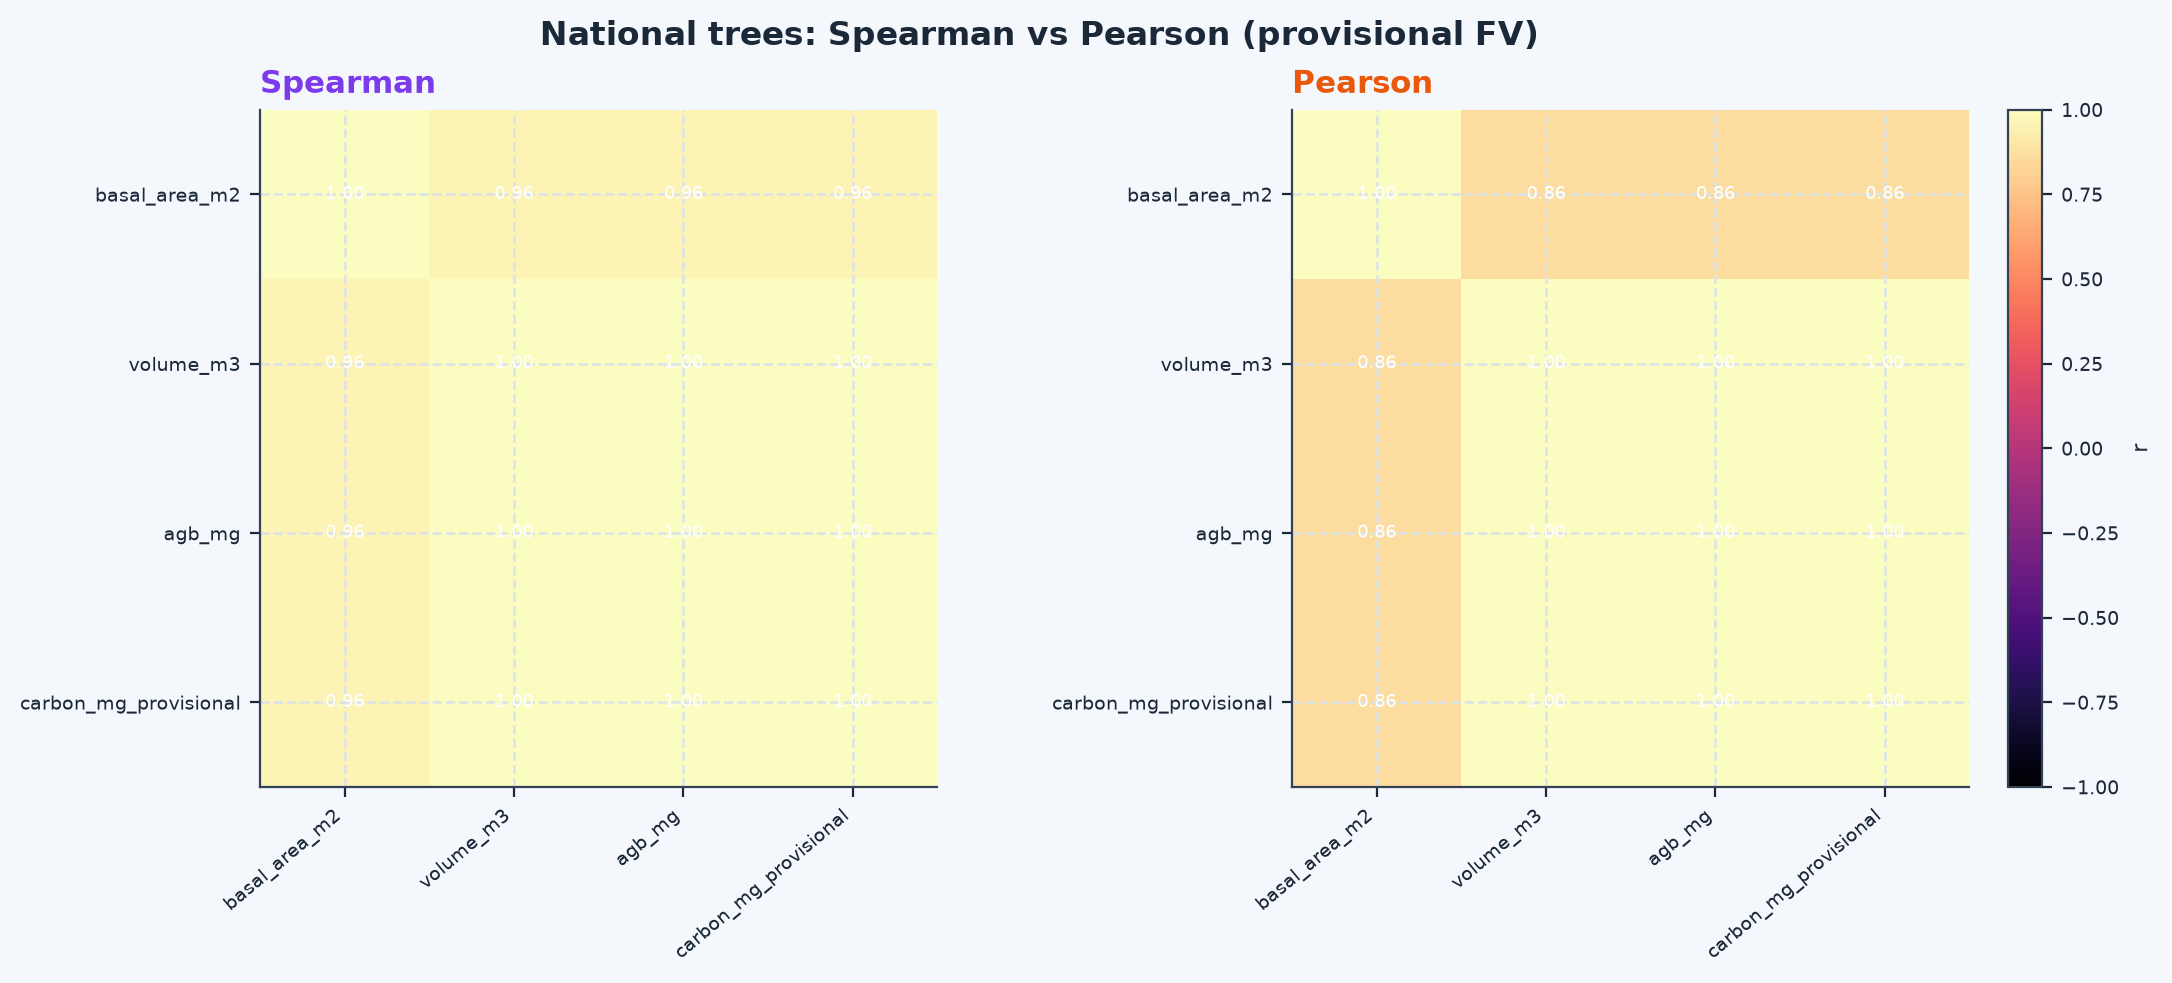

**univariate_shrubs_national.png**

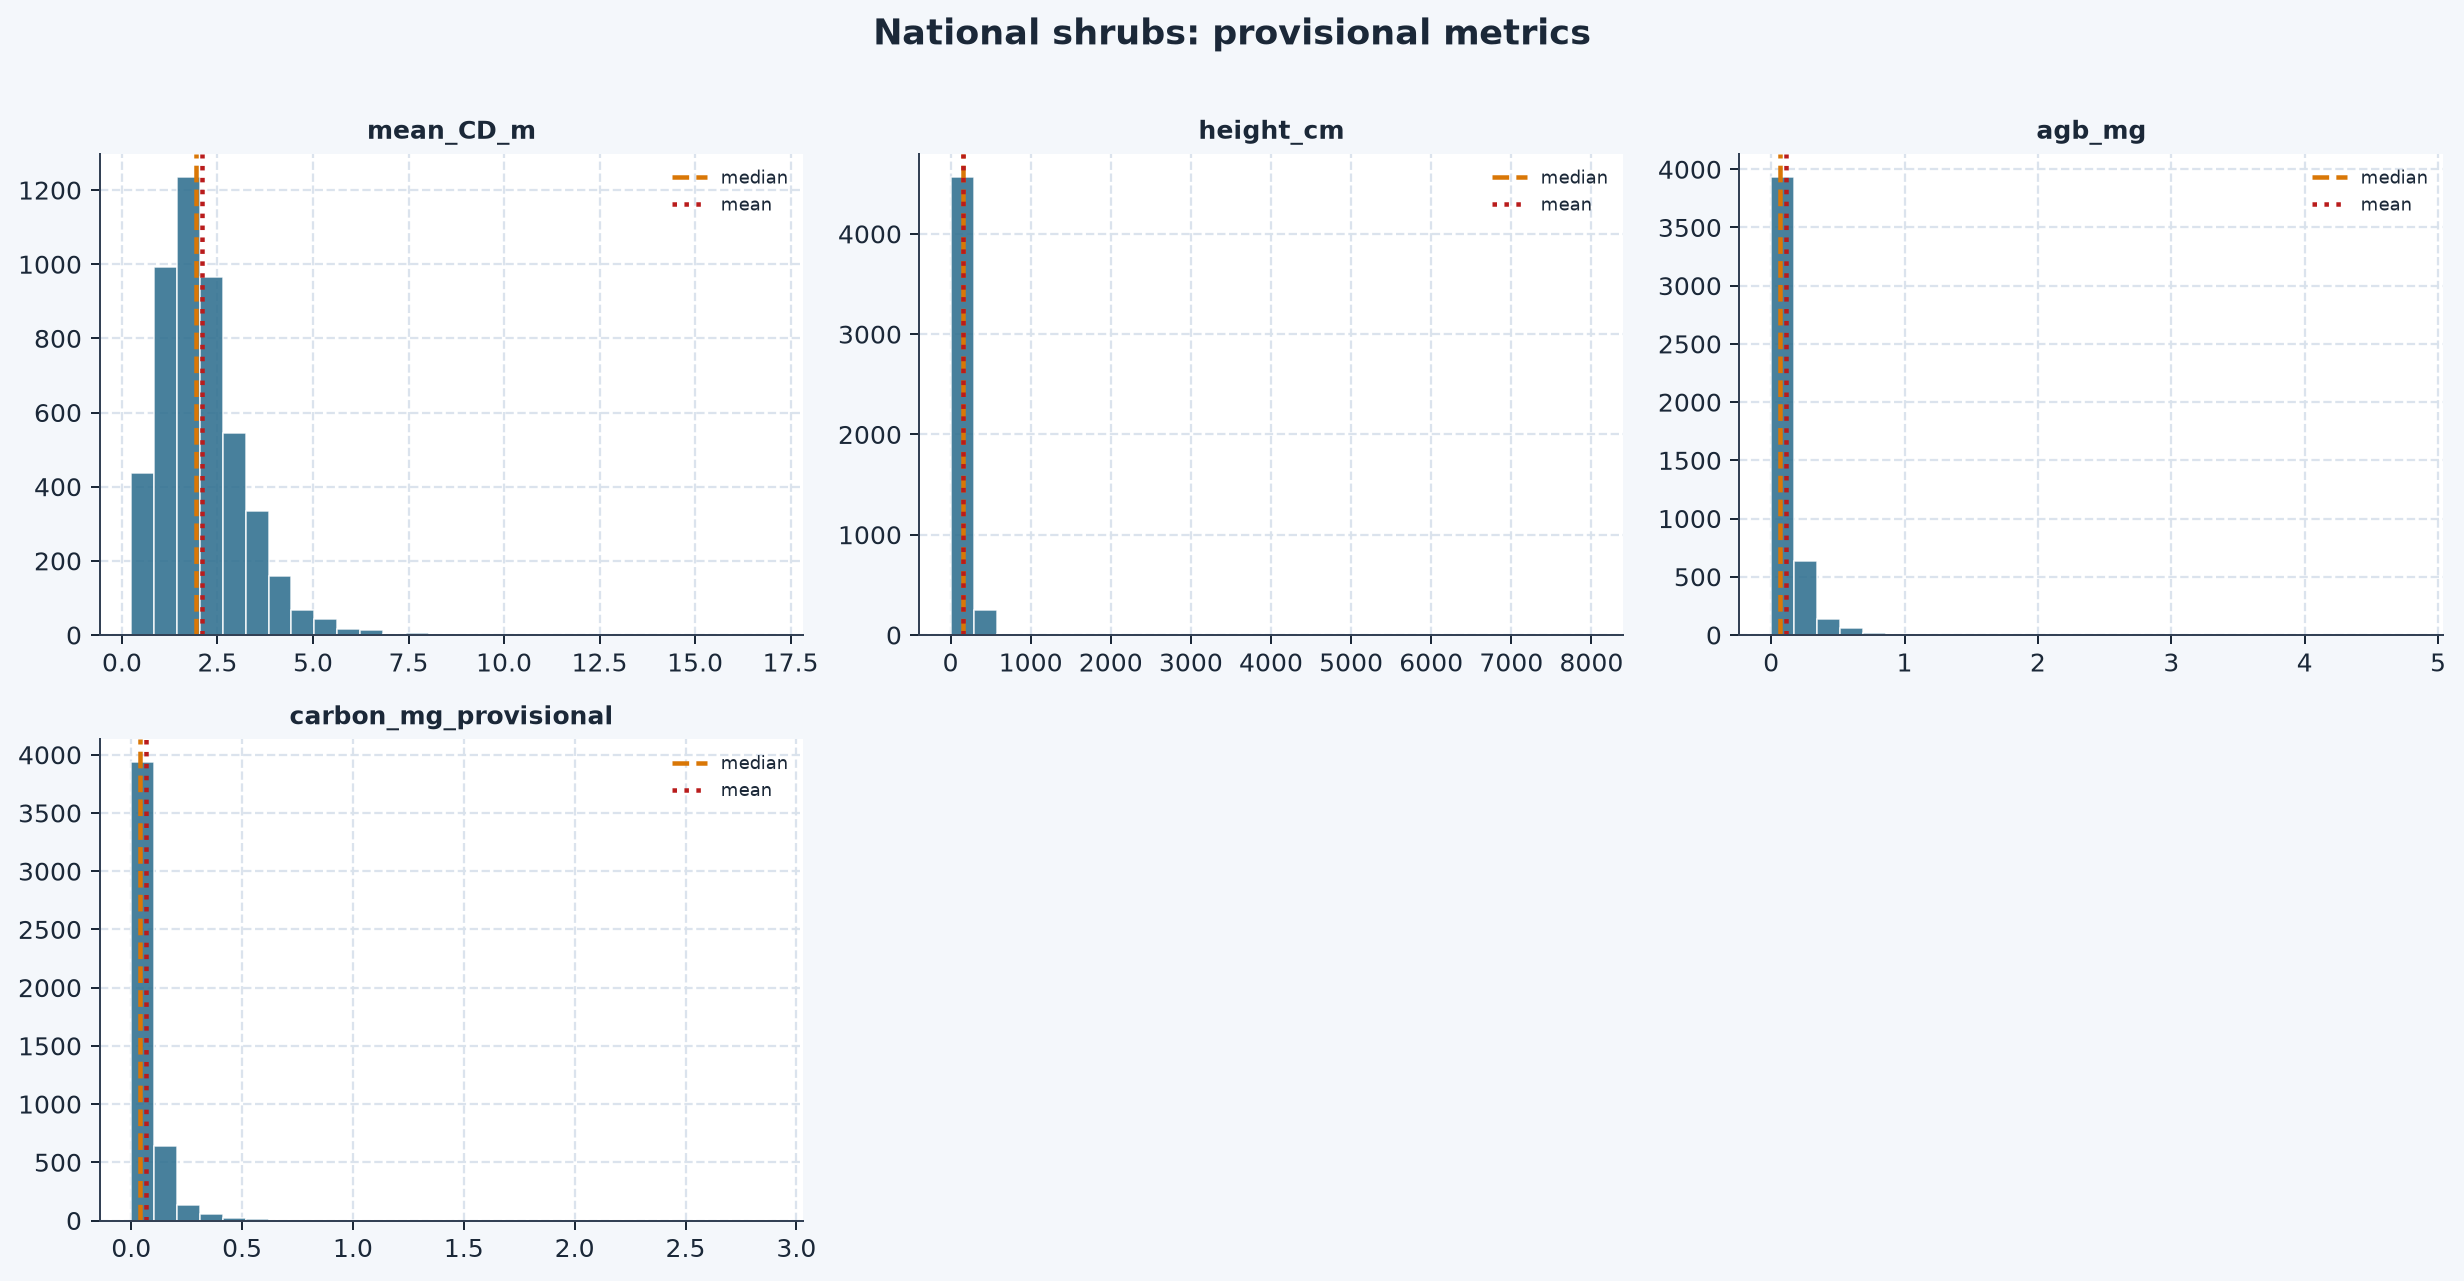

In [1]:
from nfi_datascience import bivariate_numeric

ROLLED = aggregate_plot_su_metrics(TREE_M, SHRUB_M, LATTICE)
ROLLED["plot_metrics"].to_csv(OUT / "validated" / "national_plot_biomass_sample.csv", index=False)
ROLLED["su_metrics"].to_csv(OUT / "validated" / "national_su_biomass_sample.csv", index=False)

# --- Univariate tables (also written for the HTML report) ---
UNI_T = univariate_numeric(
    TREE_M, [c for c in ["basal_area_m2", "volume_m3", "agb_mg", "carbon_mg_provisional", "co2eq_mg_provisional"] if c in TREE_M.columns]
)
UNI_S = univariate_numeric(
    SHRUB_M, [c for c in ["mean_CD_m", "height_cm", "agb_mg", "carbon_mg_provisional"] if c in SHRUB_M.columns]
)
UNI_T.to_csv(OUT / "audit" / "univariate_national_trees_fv.csv", index=False)
UNI_S.to_csv(OUT / "audit" / "univariate_national_shrubs_fv.csv", index=False)
display(Markdown("### Univariate · trees (provisional FV)"))
display(UNI_T)
display(Markdown("### Univariate · shrubs (provisional)"))
display(UNI_S)

# --- Bivariate correlation tables ---
eng_cols = [c for c in ["basal_area_m2", "volume_m3", "agb_mg", "carbon_mg_provisional"] if c in TREE_M.columns]
BIV_S = bivariate_numeric(TREE_M, eng_cols, method="spearman") if len(eng_cols) >= 2 else pd.DataFrame()
BIV_P = bivariate_numeric(TREE_M, eng_cols, method="pearson") if len(eng_cols) >= 2 else pd.DataFrame()
eda_dir = OUT / "figures" / "national_eda"
eda_dir.mkdir(parents=True, exist_ok=True)
if len(BIV_S):
    BIV_S.to_csv(eda_dir / "bivariate_spearman_trees_national.csv", index=False)
    BIV_P.to_csv(eda_dir / "bivariate_pearson_trees_national.csv", index=False)
    display(Markdown("### Bivariate · Spearman (trees)"))
    display(BIV_S)
    display(Markdown("### Bivariate · Pearson (trees)"))
    display(BIV_P)

# --- Figures inline ---
FIG_PATHS = write_national_eda_figures(trees, TREE_M, SHRUB_M, eda_dir, CFG)
display(Markdown("### Univariate and bivariate figures"))
for name, path in FIG_PATHS.items():
    print(name, "->", path)
    if path and Path(path).exists():
        display(Image(filename=str(path)))


<a id="s13"></a>
## 13 · Static national PNG maps

**User note:** Quick static maps for reports. For pan/zoom review use Section 14 interactive HTML.


In [ ]:
MAP_PATHS = write_national_maps(plot, CFG, OUT / "maps" / "national", ROLLED["su_metrics"])
for name, path in MAP_PATHS.items():
    print(name, "->", path)
    if path and Path(path).exists():
        display(Image(filename=str(path)))


<a id="s14"></a>
## 14 · Interactive Leaflet HTML maps + atlas portal

**User note:** This is the interactive map production step. Writes Folium/Leaflet HTML with Esri/Google basemaps:
- national plots (clustered)
- tree-presence gate at SU points
- provisional tree carbon
- provisional shrub carbon (when available)

Then builds an **atlas portal** (`maps/html_atlas/index.html`) so you can switch themes in one browser tab.


In [ ]:
IMAP_DIR = OUT / "maps" / "html_interactive"
ATLAS_DIR = OUT / "maps" / "html_atlas"
INTERACTIVE = write_national_interactive_maps(
    plot, CFG, LATTICE, ROLLED["su_metrics"], IMAP_DIR
)
ATLAS_INDEX = write_national_html_atlas(INTERACTIVE, ATLAS_DIR)
HTML_PRODUCTS["interactive_maps"] = INTERACTIVE
HTML_PRODUCTS["atlas_index"] = str(ATLAS_INDEX)

display(Markdown("### Interactive map files"))
display(pd.DataFrame([{"theme": k, "path": v} for k, v in INTERACTIVE.items()]))
print("Atlas portal:", ATLAS_INDEX)

# Embed atlas in notebook when the file is local (may be blank in some remote viewers)
try:
    display(IFrame(src=ATLAS_INDEX.as_uri(), width="100%", height=640))
except Exception as e:
    print("IFrame embed skipped:", e)
    display(HTML(f'<p>Open atlas: <a href="{ATLAS_INDEX.as_uri()}" target="_blank">{ATLAS_INDEX}</a></p>'))


<a id="s15"></a>
## 15 · HTML methodology report (LULC-style)

**User note:** Builds a shareable HTML report similar in role to `LULC_VALIDATION_REPORT.html`: workflow, methodology, key numbers, **univariate and bivariate** tables/figures (embedded), static maps, and buttons to the interactive atlas. Safe to re-run after Sections 12 to 14.


In [ ]:
guide_summary = {
    "scope": "national_tabular_universe",
    "n_su": SUMMARY["n_su"],
    "n_regions": SUMMARY["n_regions"],
    "n_plot_rows": SUMMARY["n_plot_rows"],
    "n_plot_uid": SUMMARY["n_plot_uid"],
    "lattice_rows": int(len(LATTICE)),
    "n_tree_biomass_rows": int(len(TREE_M)),
    "n_shrub_biomass_rows": int(len(SHRUB_M)),
    "gis_area_attached_sus": int((SU_AREA["area_status"] == "GIS_AREA_ATTACHED").sum()),
    "gis_area_blocked_sus": int((SU_AREA["area_status"] == "AREA_BLOCKED_NO_GRID").sum()),
    "design_based_estimates": False,
    "carbon_label": "provisional",
    "output_root": str(OUT),
    "gate_tree_presence": {k: GATE_T[k] for k in ("total_sus", "sus_with_trees", "sus_no_trees")},
    "gate_shrub_presence": {k: GATE_S[k] for k in ("total_sus", "sus_with_shrubs", "sus_no_shrubs")},
    "assumptions": [
        "Shrub log treated as natural log (calc extract open question).",
        "Shrub sh_height treated as metres then converted to cm when unit is missing or m.",
        "National Area_H expansion blocked except where Asir/Makkah grids attach.",
        "Biomass and carbon are provisional sample metrics, not design-based inventory totals.",
        "Deadwood, litter, regeneration, vegetation cover inventoried as counts only.",
        "Shrub CO2eq left blank: not stated in calculation DOCX shrub section.",
    ],
}
REPORT_PATH = write_national_html_report(
    out_path=OUT / "documents" / "NFI_national_geopipeline_report.html",
    run_summary=guide_summary,
    by_region=SUMMARY["by_region"],
    ancillary=ANCILLARY,
    area_cov=AREA_COV,
    gate=GATE_T,
    gate_shrub=GATE_S,
    fig_paths=FIG_PATHS,
    map_paths=MAP_PATHS,
    interactive_paths=INTERACTIVE,
    atlas_index=ATLAS_INDEX,
    uni_trees=globals().get("UNI_T"),
    uni_shrubs=globals().get("UNI_S"),
    biv_spearman=globals().get("BIV_S"),
    biv_pearson=globals().get("BIV_P"),
)
HTML_PRODUCTS["html_report"] = str(REPORT_PATH)
(OUT / "documents" / "national_html_manifest.json").write_text(
    json.dumps(HTML_PRODUCTS, indent=2), encoding="utf-8"
)
print("HTML report:", REPORT_PATH)
display(HTML(
    f'<div style="padding:12px;border:1px solid #d5ddd7;border-radius:10px;background:#e8f0e9;">'
    f'<b>Methodology HTML report</b><br/>'
    f'<a href="{REPORT_PATH.as_uri()}" target="_blank">{REPORT_PATH}</a></div>'
))
try:
    display(IFrame(src=REPORT_PATH.as_uri(), width="100%", height=640))
except Exception as e:
    print("IFrame embed skipped:", e)


<a id="s16"></a>
## 16 · One-shot full pipeline (optional shortcut)

**User note:** Equivalent to `python run_national_pipeline.py`. Includes static maps, **interactive Leaflet HTML**, atlas portal, and **HTML report**. Safe after Sections 3 to 15; refreshes the same `outputs_national_v5/` products.


In [ ]:
NAT = run_national_pipeline(CFG, out_root=OUT)
RS = NAT["run_summary"]
TABLES = NAT["tables"]
su, plot, trees, shrubs = TABLES["su"], TABLES["plot"], TABLES["trees"], TABLES["shrubs"]
SUMMARY, LATTICE = NAT["summary"], NAT["lattice"]
GATE_T, GATE_S = NAT["gate"], NAT["gate_shrub"]
SU_AREA = NAT["su_area"]
TREE_M, SHRUB_M = NAT["tree_m"], NAT["shrub_m"]
ROLLED, ANCILLARY = NAT["rolled"], NAT["ancillary"]
FIG_PATHS, MAP_PATHS = NAT["fig_paths"], NAT["map_paths"]
HTML_PRODUCTS = NAT.get("html_products") or {}
AREA_COV = SU_AREA["area_status"].value_counts(dropna=False).rename("n").reset_index()
AREA_COV.columns = ["area_status", "n"]
INTERACTIVE = HTML_PRODUCTS.get("interactive_maps") or RS.get("interactive_maps") or {}
ATLAS_INDEX = Path(HTML_PRODUCTS.get("atlas_index") or RS.get("html_atlas_index") or OUT / "maps" / "html_atlas" / "index.html")
REPORT_PATH = Path(HTML_PRODUCTS.get("html_report") or RS.get("html_report") or OUT / "documents" / "NFI_national_geopipeline_report.html")

display(Markdown("### Run summary (computed only)"))
display({k: RS[k] for k in RS if k not in ("figures", "maps", "assumptions", "interactive_maps")})
print("HTML report:", REPORT_PATH)
print("Atlas portal:", ATLAS_INDEX)
print("Interactive themes:", list(INTERACTIVE.keys()) if isinstance(INTERACTIVE, dict) else INTERACTIVE)


<a id="s17"></a>
## 17 · Verify outputs (checklist)

**User note:** Confirm CSV, PNG, interactive HTML, atlas, and report exist.


In [ ]:
expected_files = [
    OUT / "logs" / "national_run_summary.json",
    OUT / "validated" / "national_plot_lattice.csv",
    OUT / "validated" / "national_trees_biomass_provisional.csv",
    OUT / "validated" / "national_shrubs_biomass_provisional.csv",
    OUT / "audit" / "univariate_national_trees_fv.csv",
    OUT / "audit" / "univariate_national_shrubs_fv.csv",
    OUT / "figures" / "national_eda" / "univariate_trees_fv_national.png",
    OUT / "figures" / "national_eda" / "bivariate_corr_pair_trees_national.png",
    OUT / "documents" / "NFI_national_geopipeline_report.html",
    OUT / "maps" / "html_atlas" / "index.html",
    OUT / "maps" / "html_interactive" / "interactive_national_plots.html",
]
check = pd.DataFrame([
    {"path": str(p.relative_to(OUT)), "exists": p.exists(), "bytes": p.stat().st_size if p.exists() else 0}
    for p in expected_files
])
display(check)
print("All required present:", bool(check["exists"].all()))


<a id="s17b"></a>
## Deliverables · open the map HTML and methodology report

**User note:** These are the two shareable HTML products for the entire national process (analogous to `LULC_VALIDATION_REPORT.html` plus an interactive map atlas).


### Univariate / bivariate figures (rerun display)

**univariate_trees_national.png**

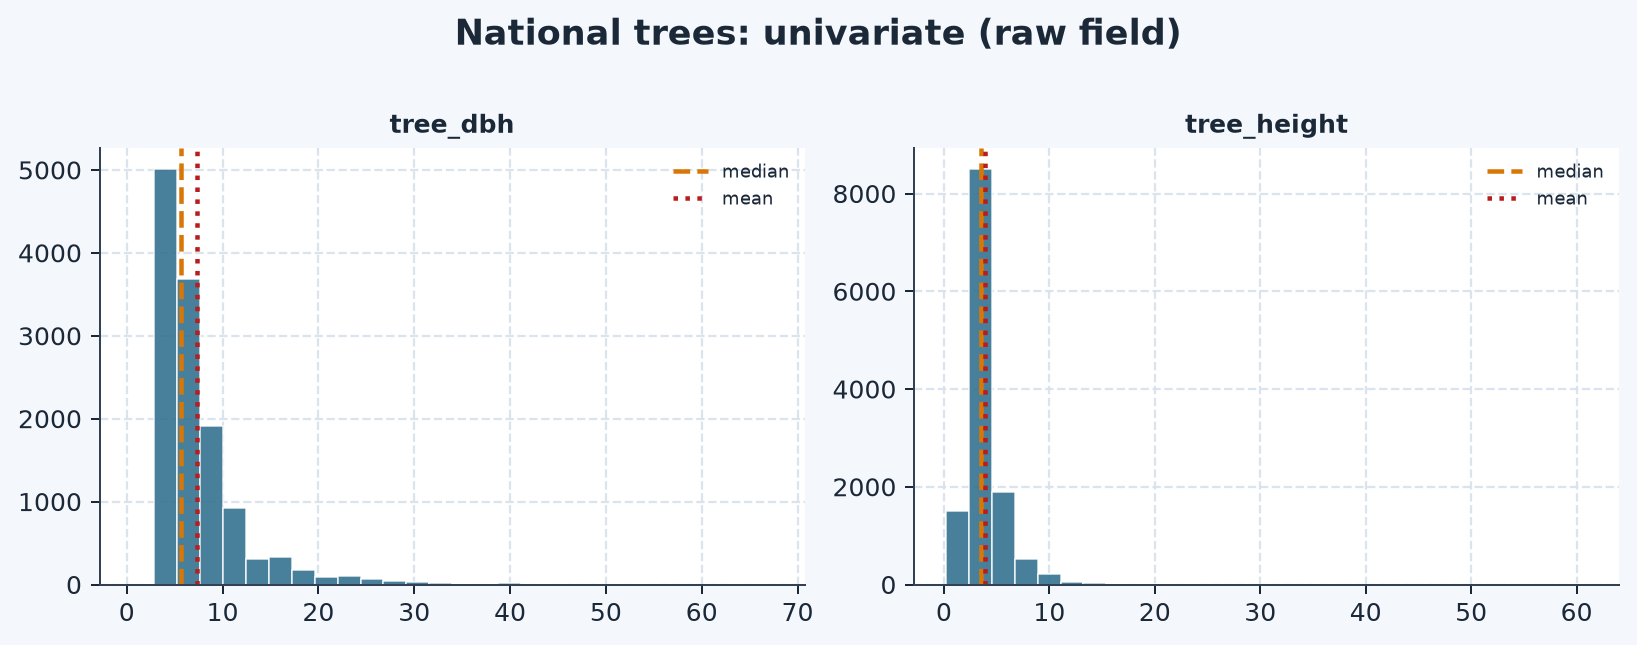

**univariate_trees_fv_national.png**

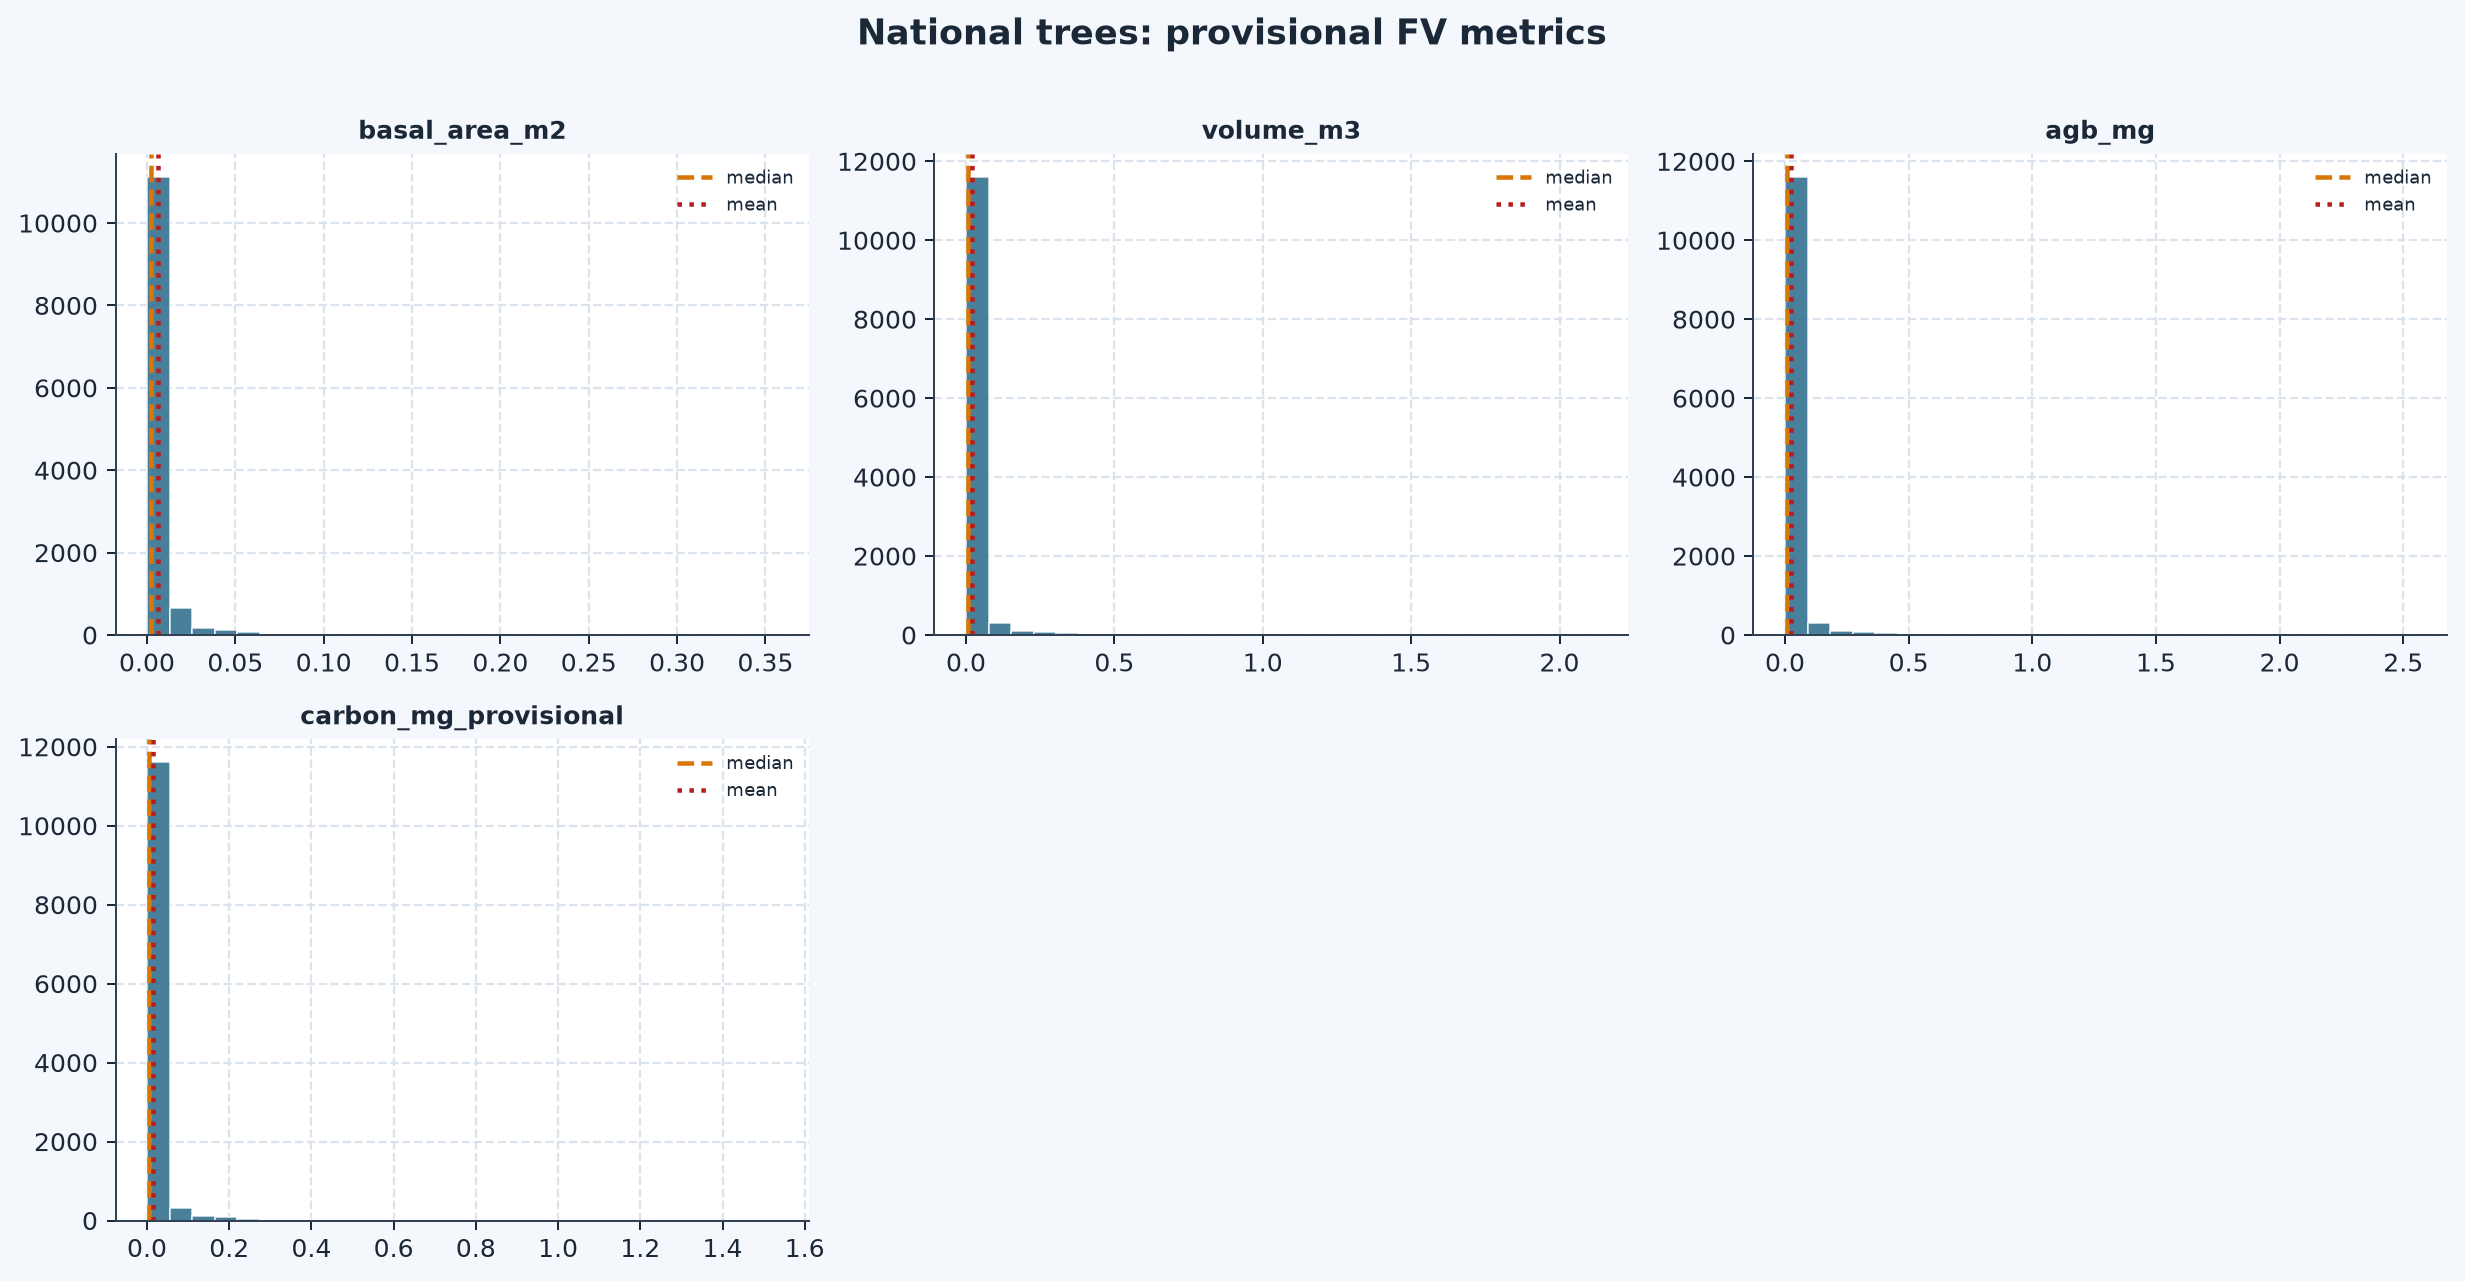

**bivariate_corr_pair_trees_national.png**

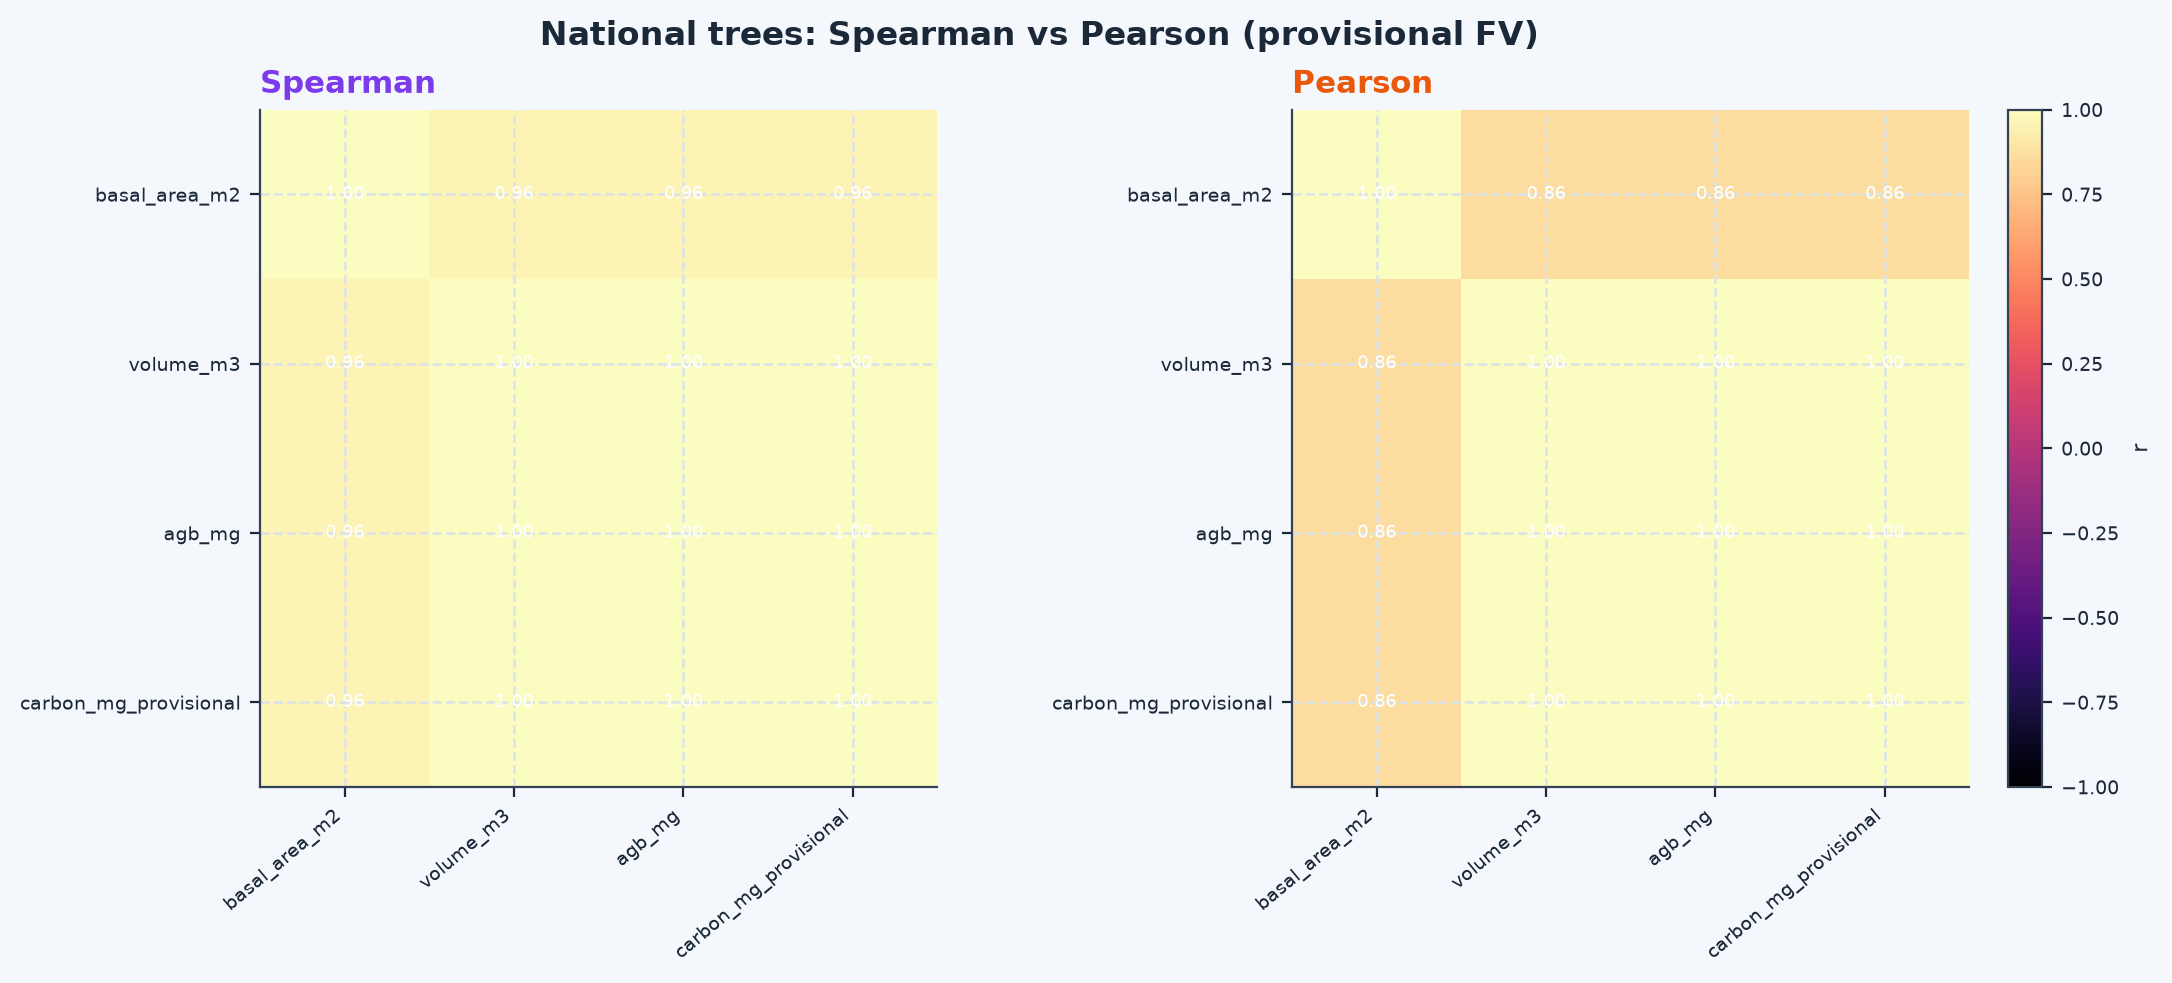

**univariate_shrubs_national.png**

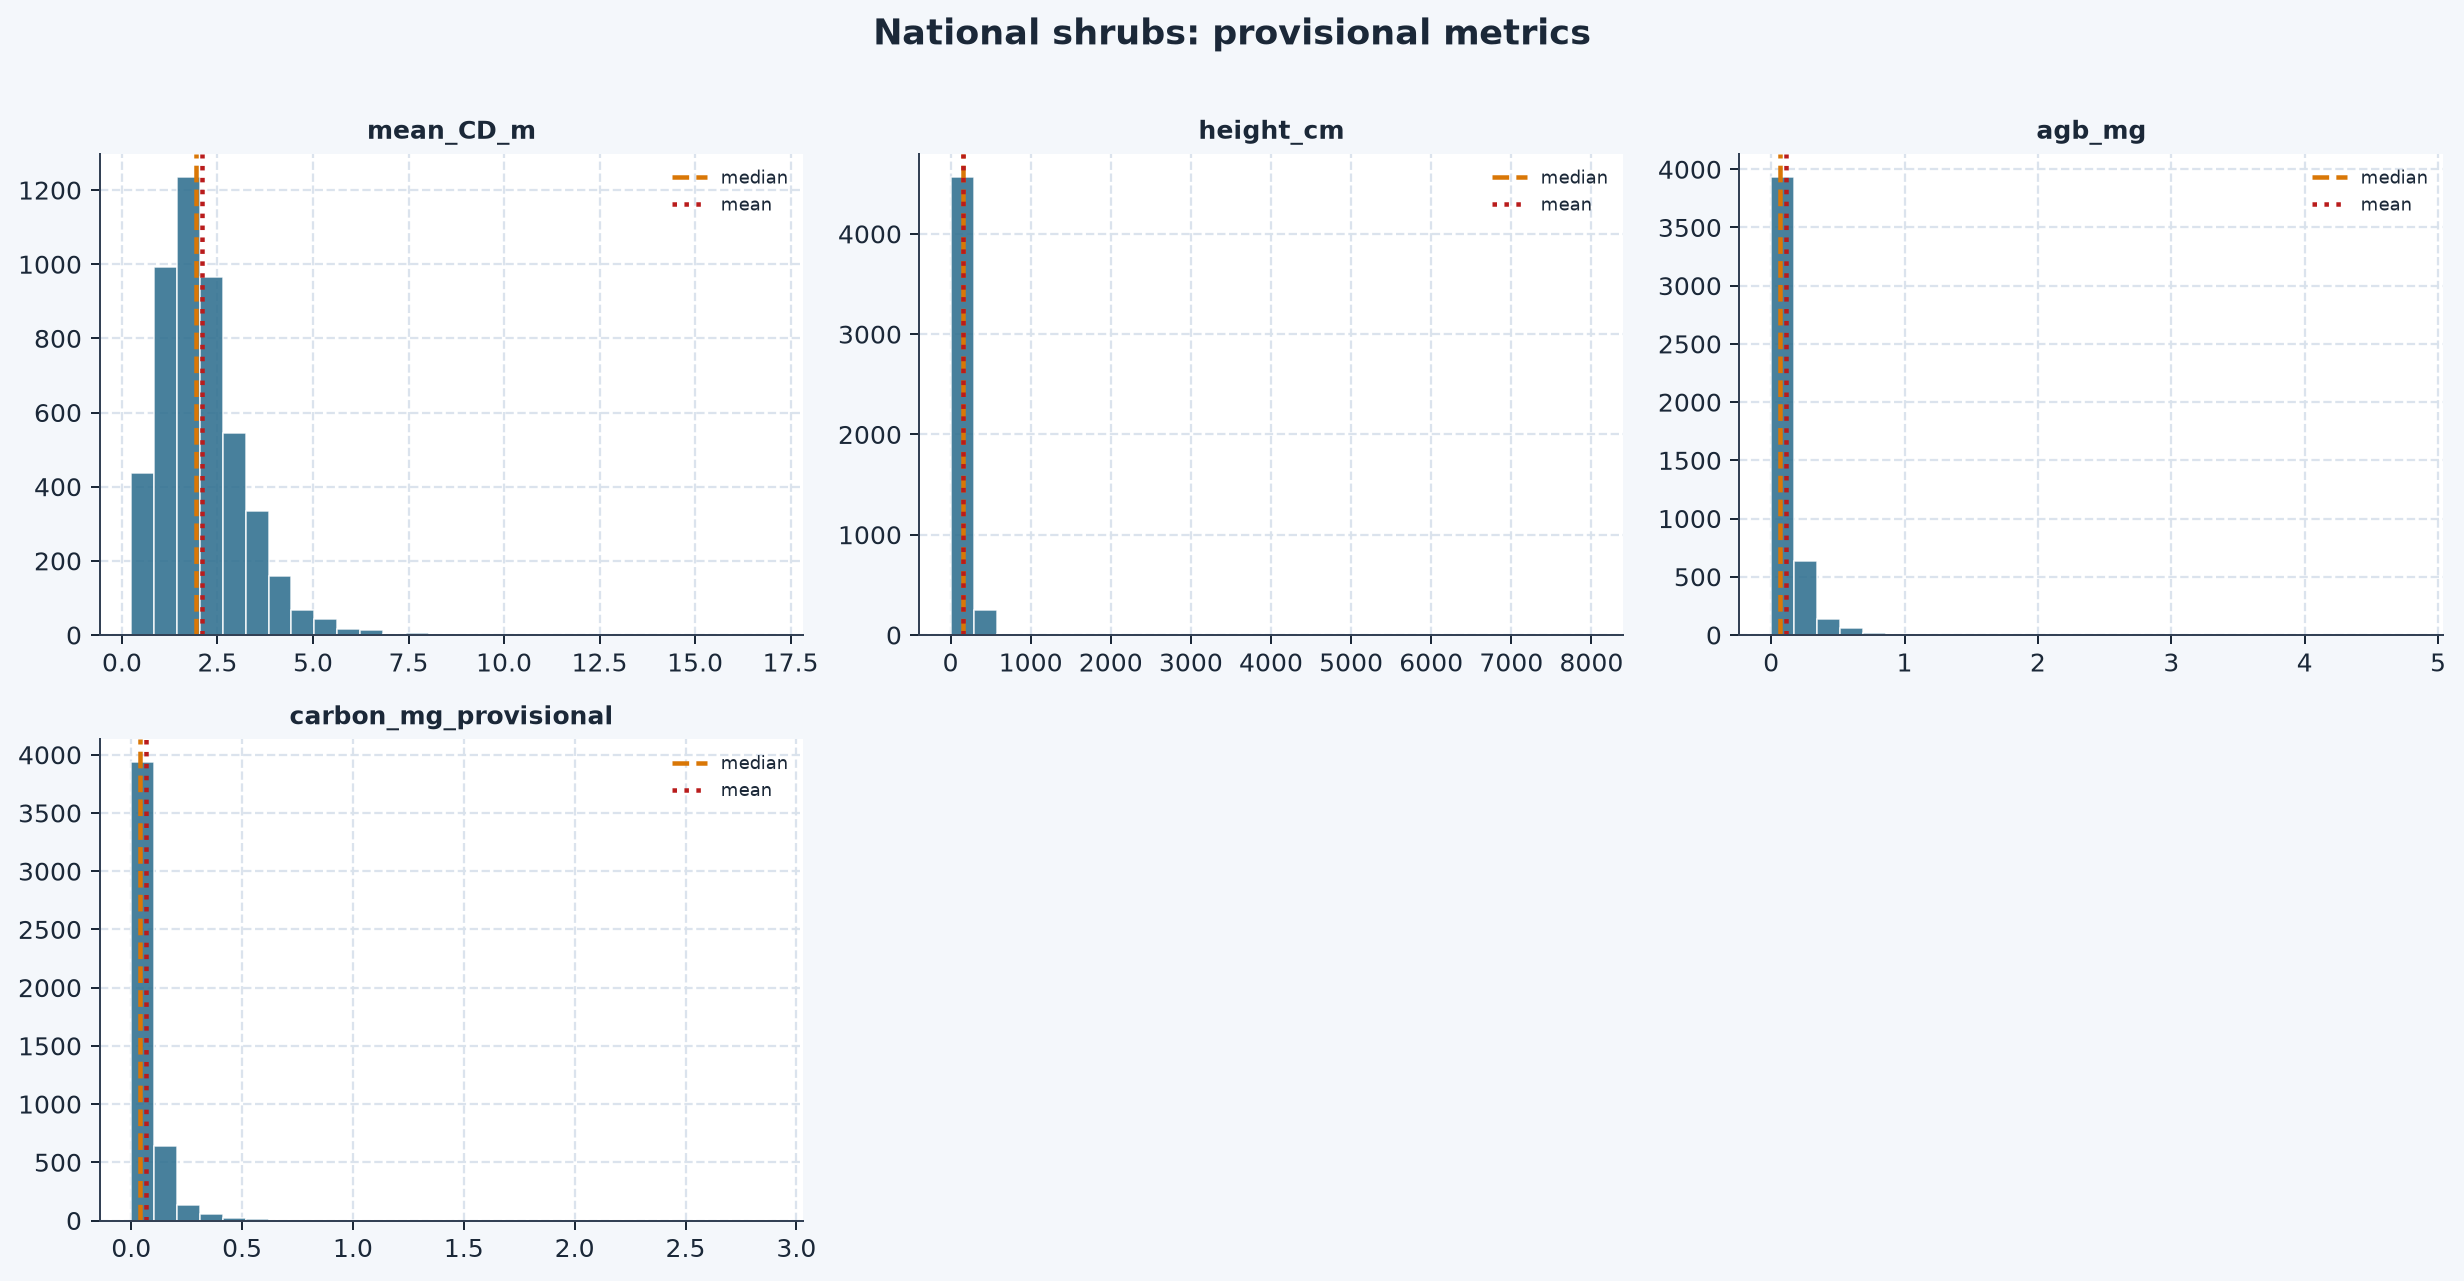

In [1]:
REPORT_PATH = Path(HTML_PRODUCTS.get("html_report") or OUT / "documents" / "NFI_national_geopipeline_report.html")
ATLAS_INDEX = Path(HTML_PRODUCTS.get("atlas_index") or OUT / "maps" / "html_atlas" / "index.html")
INTERACTIVE = HTML_PRODUCTS.get("interactive_maps") or {}
if not INTERACTIVE:
    imap = OUT / "maps" / "html_interactive"
    INTERACTIVE = {p.stem.replace("interactive_national_", ""): str(p) for p in imap.glob("interactive_national_*.html")}

# Re-show key EDA figures so they remain visible near the end of the notebook
eda = OUT / "figures" / "national_eda"
display(Markdown("### Univariate / bivariate figures (rerun display)"))
for p in [
    eda / "univariate_trees_national.png",
    eda / "univariate_trees_fv_national.png",
    eda / "bivariate_corr_pair_trees_national.png",
    eda / "univariate_shrubs_national.png",
]:
    if p.exists():
        display(Markdown(f"**{p.name}**"))
        display(Image(filename=str(p)))

links = [
    ("Methodology + results HTML report", REPORT_PATH),
    ("Interactive map atlas (Leaflet portal)", ATLAS_INDEX),
]
for name, p in INTERACTIVE.items():
    links.append((f"Interactive map · {name}", Path(p)))

rows = []
html_bits = ['<div style="font-family:IBM Plex Sans,Segoe UI,sans-serif;line-height:1.5">']
html_bits.append('<h3 style="color:#1b5e20;margin:0 0 8px">Open these HTML deliverables</h3>')
for label, path in links:
    path = Path(path)
    ok = path.exists()
    rows.append({"deliverable": label, "exists": ok, "path": str(path)})
    if ok:
        html_bits.append(
            f'<p style="margin:8px 0"><a style="display:inline-block;padding:10px 14px;background:#14351c;color:#fff;'
            f'text-decoration:none;border-radius:8px;font-weight:600" href="{path.as_uri()}" target="_blank">{label}</a>'
            f'<br/><code style="font-size:12px">{path}</code></p>'
        )
    else:
        html_bits.append(f'<p style="color:#a33">Missing: {label} ({path})</p>')
html_bits.append("</div>")
display(HTML("".join(html_bits)))
display(pd.DataFrame(rows))

try:
    display(Markdown("### Atlas preview"))
    display(IFrame(src=ATLAS_INDEX.as_uri(), width="100%", height=520))
except Exception as e:
    print("Atlas iframe skipped:", e)
try:
    display(Markdown("### Report preview"))
    display(IFrame(src=REPORT_PATH.as_uri(), width="100%", height=640))
except Exception as e:
    print("Report iframe skipped:", e)


<a id="s18"></a>
## 18 · Assumptions and open questions

1. Shrub allometric `log` treated as **natural log** (base not stated in the calc DOCX).
2. Total biomass = AGB + BGB is implied by the carbon chain.
3. DBH unit centimetres implied by basal-area divisor 40000.
4. Shrub `sh_height` treated as metres (×100 → cm) when unit is missing and median height is under 20.
5. Shrub CO2eq not computed (not stated in the shrub section).
6. National Area_H expansion blocked except where Asir/Makkah grids attach.
7. Design weights unavailable → design-based national estimates blocked.
8. Deadwood / litter / regeneration / vegetation cover: counts only until official equations are supplied.
9. Interactive plot map may sample markers for browser performance (seeded); presence and carbon maps use SU representatives.
10. Tabular Aseer region count in the SU master differs from the Asir GIS 430-SU analytical grid used in Part A.

See also: `docs/ASSUMPTIONS_AND_OPEN_QUESTIONS.md` and `../docs/04_national_pipeline.md`.


---
## Appendix A · CLI twin

```text
cd 12.NFI_Comprehensive_Expanded_V5
python run_national_pipeline.py
```

Produces the same CSVs, PNGs, interactive HTML maps, atlas portal, and HTML report.

## Appendix B · Output folder map

| Folder | Role |
| --- | --- |
| `audit/` | KPIs, missingness, area coverage, ancillary counts |
| `validated/` | Lattice, biomass tables, LU proportions, optional Area_H |
| `gates/` | Zero-tree and zero-shrub SU lists |
| `figures/national_eda/` | Univariate and bivariate charts |
| `maps/national/` | Static PNG maps |
| `maps/html_interactive/` | Leaflet HTML maps (plots, gates, carbon) |
| `maps/html_atlas/` | Interactive atlas portal (`index.html`) |
| `documents/` | HTML report + HTML manifest |
| `logs/` | `national_run_summary.json` receipt |
| `stages/` | StageStore snapshots |

## Appendix C · Deeper regional / LULC work

`NFI_GeoAI_Comprehensive_Expanded_V5.ipynb` keeps Part A (Asir GIS depth) and Part B (LULC validation). **This guide notebook is the national-first entry point.**

## Appendix D · Key source modules

| Module | Role |
| --- | --- |
| `src/nfi_national_pipeline.py` | National ingest → gates → biomass → EDA → maps |
| `src/nfi_national_html.py` | Interactive Leaflet maps, atlas portal, HTML report |
| `src/nfi_calc_biomass.py` | Tree and shrub formulas from the calc DOCX |
| `src/nfi_audit.py` | Keys, StageStore, coordinate QA, config |
| `src/nfi_datascience.py` | Univariate / bivariate plotting helpers |
| `config.yaml` | Paths, design constants, policy flags |
